In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr, ndtri
from scipy.stats import qmc
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/snr_sweep.py").is_file():
    raise RuntimeError("Run from the project root or notebooks/ using lya_ml.")

CACHE_ONLY = True
AGGREGATION_SOURCE = "raw"

# Existing training artifacts: inputs only.
CACHE_ROOT = ROOT / "outputs/cos_lsf_snr/perchunk_tuned"

# All corrected downstream products will go here.
OUT = CACHE_ROOT / "raw_combination"
if OUT.resolve() == CACHE_ROOT.resolve():
    raise RuntimeError("Analysis output must differ from the cache input root.")

MODELS = ("EX0", "EX1", "EX2", "EX3")
SNRS = (10, 15, 20, 30, 50, 80)
NOISE_SEEDS = (20260929, 20260930, 20261001)
PLOT_SNRS = (10, 20, 30, 50)
TASKS = {
    "EX0_EX3": ("EX0", "EX3"),
    "EX2_EX3": ("EX2", "EX3"),
    "EX0_EX2": ("EX0", "EX2"),
    "EX0_EX1": ("EX0", "EX1"),
    "four_class": MODELS,
}
TASK_LABELS = {
    task: "four-class" if len(models) == 4 else "–".join(models)
    for task, models in TASKS.items()
}

# Preserve the existing analysis settings.
SEED = 20261011
EPS = 1e-6
DIRECT_DRAWS = 10_000
DIRECT_MAX_N = 200
GAUSSIAN_MAX_N = 10_000
GAUSSIAN_SOBOL_POWER = 15
CHECK_NS = (50, 100, 150, 200)
CHECK_ABS_TOL = 0.02
BASELINE_BOOTSTRAPS = 5000
EXPECTED_QA_CHUNKS = 1113

QA_MIX_CSV = None
QA_MAPPING_RULE = None

MANIFEST_PATH = ROOT / "outputs/uvb_mean_flux/manifests/z0_b15_seed42.npz"
BASELINE_PATH = (
    ROOT / "outputs/cos_lsf_snr/snr_sweep/summary/bootstrap_inputs.npz"
)
SIGNATURE_PATH = CACHE_ROOT / "training_signature.json"
SPLIT_PATH = CACHE_ROOT / "grouped_split.npz"

required = [MANIFEST_PATH, BASELINE_PATH, SIGNATURE_PATH, SPLIT_PATH]
required += [CACHE_ROOT / "tuning" / task / "winner.json" for task in TASKS]
for snr in SNRS:
    for task in TASKS:
        folder = CACHE_ROOT / "models" / f"snr{snr}" / task
        required.extend(
            folder / name
            for name in (
                "test_probabilities.npz",
                "completed.json",
                "booster.json",
                "isotonic.joblib",
            )
        )

missing = [str(path.relative_to(ROOT)) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Cache-only analysis requires these existing files:\n"
        + "\n".join(missing)
    )

empty = [str(path.relative_to(ROOT)) for path in required if path.stat().st_size == 0]
if empty:
    raise ValueError("Empty cache inputs:\n" + "\n".join(empty))

# Read the original signature; do not regenerate or overwrite it.
training_signature = json.loads(SIGNATURE_PATH.read_text(encoding="utf-8"))
expected = {
    "schema": 1,
    "models": list(MODELS),
    "tasks": {task: list(models) for task, models in TASKS.items()},
    "snr_levels": list(SNRS),
    "noise_seeds": list(NOISE_SEEDS),
    "seed": SEED,
    "epsilon": EPS,
}
for key, value in expected.items():
    if training_signature.get(key) != value:
        raise ValueError(
            f"Cached training signature mismatch for {key!r}: "
            f"saved={training_signature.get(key)!r}, expected={value!r}"
        )

print(f"Input preflight passed: {len(required)} nonempty files.")
print("Saved training configuration matches the requested setup.")
print(f"Aggregation source: {AGGREGATION_SOURCE}")
print(f"Analysis destination: {OUT}")
print("No files written. Prediction-array validation is the next step.")

Input preflight passed: 129 nonempty files.
Saved training configuration matches the requested setup.
Aggregation source: raw
Analysis destination: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/perchunk_tuned/raw_combination
No files written. Prediction-array validation is the next step.


In [2]:
SEARCH_SPACE={
    "max_depth":[2,3,4,6],"learning_rate":[0.03,0.1],
    "min_child_weight":[1,10,50],"subsample":[0.7,1.0],
    "colsample_bytree":[0.5,1.0],"reg_lambda":[1.0,10.0],
}
names=list(SEARCH_SPACE)
grid=[dict(zip(names,v)) for v in product(*(SEARCH_SPACE[name] for name in names))]
trial_indices=np.random.default_rng(SEED).choice(len(grid),size=N_TRIALS,replace=False)
TRIALS=[grid[int(i)] for i in trial_indices]


def normalize_probabilities(p):
    p=np.asarray(p,dtype=float)
    if p.ndim==1:
        p=np.column_stack([1-p,p])
    if not np.all(np.isfinite(p)) or np.any(p<0):
        raise ValueError("Invalid model probabilities.")
    total=p.sum(axis=1,keepdims=True)
    p=np.divide(p,total,out=np.full_like(p,1/p.shape[1]),where=total>0)
    p=np.clip(p,EPS,1-EPS)
    return p/p.sum(axis=1,keepdims=True)


def fit_booster(dtrain,dtune,params,n_class):
    config={**params,"tree_method":"hist","nthread":NTHREAD,"seed":SEED,"verbosity":0,
            "objective":"binary:logistic" if n_class==2 else "multi:softprob",
            "eval_metric":"logloss" if n_class==2 else "mlogloss"}
    if n_class>2:
        config["num_class"]=n_class
    booster=xgb.train(config,dtrain,num_boost_round=MAX_ROUNDS,
                      evals=[(dtune,"tune")],early_stopping_rounds=EARLY_STOPPING,
                      verbose_eval=False)
    rounds=int(booster.best_iteration)+1
    return booster,rounds


def predict_booster(booster,matrix,rounds):
    return normalize_probabilities(booster.predict(matrix,iteration_range=(0,rounds)))


def fit_isotonic(raw,y):
    if raw.shape[1]==2:
        return [IsotonicRegression(out_of_bounds="clip",y_min=0,y_max=1).fit(raw[:,1],y==1)]
    return [IsotonicRegression(out_of_bounds="clip",y_min=0,y_max=1).fit(raw[:,j],y==j)
            for j in range(raw.shape[1])]


def apply_isotonic(calibrators,raw):
    if raw.shape[1]==2:
        p1=calibrators[0].predict(raw[:,1])
        p=np.column_stack([1-p1,p1])
    else:
        p=np.column_stack([iso.predict(raw[:,j]) for j,iso in enumerate(calibrators)])
    fraction_clipped=float(np.mean((p<=EPS)|(p>=1-EPS)))
    return normalize_probabilities(p),fraction_clipped


def tie_credit(scores,true_class):
    winners=np.isclose(scores,scores.max(axis=-1,keepdims=True),rtol=0,atol=1e-12)
    return winners[...,true_class]/winners.sum(axis=-1)


training_source="\n\n".join(inspect.getsource(f) for f in
    (load_features,task_matrix,normalize_probabilities,fit_booster,predict_booster,
     fit_isotonic,apply_isotonic))
training_signature={
    "schema":1,"manifest_sha256":manifest_hash,"feature_sha256":feature_hashes,
    "models":list(MODELS),"tasks":{key:list(value) for key,value in TASKS.items()},
    "snr_levels":list(SNRS),"noise_seeds":list(NOISE_SEEDS),
    "split_sha256":hashlib.sha256(all_groups.astype("<i8").tobytes()).hexdigest(),
    "seed":SEED,"trials":TRIALS,"max_rounds":MAX_ROUNDS,"early_stopping":EARLY_STOPPING,
    "epsilon":EPS,"nthread":NTHREAD,"code_sha256":hashlib.sha256(training_source.encode()).hexdigest(),
    "versions":{"numpy":np.__version__,"xgboost":xgb.__version__,"sklearn":sklearn.__version__},
}
TRAINING_KEY=json_hash(training_signature)
receipt_path=OUT/"training_signature.json"
if receipt_path.exists() and json.loads(receipt_path.read_text())!=training_signature:
    raise RuntimeError("Training settings or inputs changed. Choose a new OUT directory to preserve completed runs.")
write_json(receipt_path,training_signature)
save_npz(OUT/"grouped_split.npz",fit_los=fit_los,tune_los=tune_los,
         calibration_los=calibration_los,test_los=test_los,
         test_bundle_ids=test_bundle_ids,seed=np.array(SEED))


In [3]:
cube20=load_features(20)
winners={}
tuning_rows=[]
for task,models in TASKS.items():
    folder=OUT/"tuning"/task
    folder.mkdir(parents=True,exist_ok=True)
    xfit,yfit=task_matrix(cube20,models,fit_los)
    xtune,ytune=task_matrix(cube20,models,tune_los)
    dfit=xgb.DMatrix(xfit,label=yfit,nthread=NTHREAD)
    dtune=xgb.DMatrix(xtune,label=ytune,nthread=NTHREAD)
    records=[]
    for trial,params in enumerate(TRIALS):
        checkpoint=folder/f"trial_{trial:02d}.json"
        if checkpoint.is_file():
            record=json.loads(checkpoint.read_text())
            if record["training_key"]!=TRAINING_KEY or record["parameters"]!=params:
                raise RuntimeError(f"Stale tuning checkpoint: {checkpoint}")
        else:
            booster,rounds=fit_booster(dfit,dtune,params,len(models))
            score=float(log_loss(ytune,predict_booster(booster,dtune,rounds),
                                 labels=np.arange(len(models))))
            record={"task":task,"trial":trial,"parameters":params,"rounds":rounds,
                    "validation_logloss":score,"training_key":TRAINING_KEY}
            write_json(checkpoint,record)
        records.append(record)
        tuning_rows.append({k:v for k,v in record.items() if k not in ("parameters","training_key")}
                           |record["parameters"])
        print(f"{TASK_LABELS[task]} trial {trial+1:02d}/{N_TRIALS}: "
              f"log-loss={record['validation_logloss']:.6f}, rounds={record['rounds']}",flush=True)
    winner=min(records,key=lambda row:(row["validation_logloss"],row["trial"]))
    winners[task]=winner
    write_json(folder/"winner.json",winner)
    del dfit,dtune,xfit,xtune
pd.DataFrame(tuning_rows).to_csv(OUT/"tuning_results.csv",index=False)
display(pd.DataFrame([{"task":TASK_LABELS[t],"validation_logloss":w["validation_logloss"],
                      "rounds_at_snr20":w["rounds"],**w["parameters"]}
                     for t,w in winners.items()]))
del cube20


EX0–EX3 trial 01/30: log-loss=0.690499, rounds=35
EX0–EX3 trial 02/30: log-loss=0.690304, rounds=86
EX0–EX3 trial 03/30: log-loss=0.690587, rounds=37
EX0–EX3 trial 04/30: log-loss=0.690709, rounds=34
EX0–EX3 trial 05/30: log-loss=0.690396, rounds=47
EX0–EX3 trial 06/30: log-loss=0.690418, rounds=83
EX0–EX3 trial 07/30: log-loss=0.690663, rounds=176
EX0–EX3 trial 08/30: log-loss=0.690881, rounds=84
EX0–EX3 trial 09/30: log-loss=0.690478, rounds=81
EX0–EX3 trial 10/30: log-loss=0.690403, rounds=34
EX0–EX3 trial 11/30: log-loss=0.690655, rounds=123
EX0–EX3 trial 12/30: log-loss=0.690547, rounds=31
EX0–EX3 trial 13/30: log-loss=0.690796, rounds=11
EX0–EX3 trial 14/30: log-loss=0.690608, rounds=38
EX0–EX3 trial 15/30: log-loss=0.690846, rounds=76
EX0–EX3 trial 16/30: log-loss=0.690498, rounds=132
EX0–EX3 trial 17/30: log-loss=0.690873, rounds=111
EX0–EX3 trial 18/30: log-loss=0.690530, rounds=31
EX0–EX3 trial 19/30: log-loss=0.690294, rounds=64
EX0–EX3 trial 20/30: log-loss=0.690856, rounds

,task,validation_logloss,rounds_at_snr20,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
0,EX0–EX3,0.690069,63,6,0.03,1,0.7,1.0,1.0
1,EX2–EX3,0.682228,127,6,0.03,50,1.0,0.5,1.0
2,EX0–EX2,0.688940,78,6,0.03,1,0.7,1.0,1.0
3,EX0–EX1,0.692825,24,3,0.10,10,0.7,1.0,10.0
4,four-class,1.379026,124,6,0.03,50,1.0,0.5,1.0


In [4]:
PREDICTIONS={}
chunk_rows=[]
for snr in SNRS:
    cube=load_features(snr)
    for task,models in TASKS.items():
        k=len(models)
        folder=OUT/"models"/f"snr{snr}"/task
        folder.mkdir(parents=True,exist_ok=True)
        prediction_path=folder/"test_probabilities.npz"
        completion_path=folder/"completed.json"
        if completion_path.is_file() and prediction_path.is_file():
            done=json.loads(completion_path.read_text())
            if done["training_key"]!=TRAINING_KEY:
                raise RuntimeError(f"Stale training checkpoint: {folder}")
            with np.load(prediction_path,allow_pickle=False) as saved:
                np.testing.assert_array_equal(saved["test_los"],test_los)
                np.testing.assert_array_equal(saved["models"],models)
                np.testing.assert_array_equal(saved["noise_seeds"],NOISE_SEEDS)
                raw=saved["raw_probabilities"]
                calibrated=saved["calibrated_probabilities"]
            rounds=done["rounds"]
            clip_fraction=done["calibration_boundary_fraction"]
        else:
            xfit,yfit=task_matrix(cube,models,fit_los)
            xtune,ytune=task_matrix(cube,models,tune_los)
            dfit=xgb.DMatrix(xfit,label=yfit,nthread=NTHREAD)
            dtune=xgb.DMatrix(xtune,label=ytune,nthread=NTHREAD)
            booster,rounds=fit_booster(dfit,dtune,winners[task]["parameters"],k)
            xcal,ycal=task_matrix(cube,models,calibration_los)
            raw_cal=predict_booster(booster,xgb.DMatrix(xcal,nthread=NTHREAD),rounds)
            calibrators=fit_isotonic(raw_cal,ycal)
            xtest,ytest=task_matrix(cube,models,test_los)
            raw_flat=predict_booster(booster,xgb.DMatrix(xtest,nthread=NTHREAD),rounds)
            cal_flat,clip_fraction=apply_isotonic(calibrators,raw_flat)
            # The matrix builder orders rows by true model, then seed, then LOS.
            raw=raw_flat.reshape(k,len(NOISE_SEEDS),len(test_los),k).transpose(1,0,2,3)
            calibrated=cal_flat.reshape(k,len(NOISE_SEEDS),len(test_los),k).transpose(1,0,2,3)
            booster[:rounds].save_model(folder/"booster.json")
            joblib.dump(calibrators,folder/"isotonic.joblib")
            save_npz(prediction_path,raw_probabilities=raw,calibrated_probabilities=calibrated,
                     test_los=test_los,models=np.asarray(models),noise_seeds=np.asarray(NOISE_SEEDS))
            done={"training_key":TRAINING_KEY,"snr":snr,"task":task,"rounds":rounds,
                  "parameters":winners[task]["parameters"],
                  "calibration_boundary_fraction":clip_fraction}
            write_json(completion_path,done)
            del dfit,dtune,xfit,xtune,xcal,xtest,booster,calibrators
        expected_shape=(len(NOISE_SEEDS),k,len(test_los),k)
        if raw.shape!=expected_shape or calibrated.shape!=expected_shape:
            raise ValueError(f"Wrong probability shape: {folder}")
        for probabilities in (raw,calibrated):
            if not np.all(np.isfinite(probabilities)) or np.any(probabilities<=0):
                raise ValueError("Invalid saved probabilities.")
            np.testing.assert_allclose(probabilities.sum(axis=-1),1,atol=1e-7)
        PREDICTIONS[(task,snr)]={"raw":raw,"calibrated":calibrated}
        y=np.repeat(np.arange(k),len(test_los))
        for r,seed in enumerate(NOISE_SEEDS):
            for name,p in (("raw",raw),("isotonic",calibrated)):
                flat=p[r].reshape(-1,k)
                accuracy=float(np.mean([tie_credit(p[r,c],c).mean() for c in range(k)]))
                brier=float(np.mean(np.sum((flat-np.eye(k)[y])**2,axis=1)))
                chunk_rows.append(dict(task=task,snr=snr,noise_seed=seed,calibration=name,
                                       accuracy=accuracy,logloss=float(log_loss(y,flat,labels=np.arange(k))),
                                       multiclass_brier=brier,rounds=rounds,
                                       calibration_boundary_fraction=clip_fraction))
        print(f"Saved {TASK_LABELS[task]}, S/N {snr}: {rounds} rounds; "
              f"isotonic boundary entries {clip_fraction:.2%}",flush=True)
    del cube
chunk_scores=pd.DataFrame(chunk_rows)
chunk_scores.to_csv(OUT/"per_chunk_scores_by_seed.csv",index=False)
display(chunk_scores.groupby(["task","snr","calibration"])[["accuracy","logloss"]].mean())


Saved EX0–EX3, S/N 10: 32 rounds; isotonic boundary entries 0.00%
Saved EX2–EX3, S/N 10: 100 rounds; isotonic boundary entries 0.61%
Saved EX0–EX2, S/N 10: 81 rounds; isotonic boundary entries 0.02%
Saved EX0–EX1, S/N 10: 6 rounds; isotonic boundary entries 0.18%
Saved four-class, S/N 10: 136 rounds; isotonic boundary entries 0.19%
Saved EX0–EX3, S/N 15: 38 rounds; isotonic boundary entries 0.05%
Saved EX2–EX3, S/N 15: 94 rounds; isotonic boundary entries 0.49%
Saved EX0–EX2, S/N 15: 58 rounds; isotonic boundary entries 0.07%
Saved EX0–EX1, S/N 15: 2 rounds; isotonic boundary entries 0.00%
Saved four-class, S/N 15: 127 rounds; isotonic boundary entries 0.14%
Saved EX0–EX3, S/N 20: 63 rounds; isotonic boundary entries 0.02%
Saved EX2–EX3, S/N 20: 127 rounds; isotonic boundary entries 0.34%
Saved EX0–EX2, S/N 20: 78 rounds; isotonic boundary entries 0.11%
Saved EX0–EX1, S/N 20: 24 rounds; isotonic boundary entries 0.00%
Saved four-class, S/N 20: 124 rounds; isotonic boundary entries 0.16

accuracy   logloss
task       snr calibration                    
EX0_EX1    10  isotonic     0.507338  0.703435
               raw          0.506882  0.693022
           15  isotonic     0.514096  0.693627
               raw          0.514096  0.692999
           20  isotonic     0.509163  0.693202
               raw          0.511111  0.692700
           30  isotonic     0.505887  0.694224
               raw          0.506633  0.693019
           50  isotonic     0.512604  0.695931
               raw          0.510199  0.692386
           80  isotonic     0.524959  0.700661
               raw          0.523632  0.691023
EX0_EX2    10  isotonic     0.510116  0.693460
               raw          0.506882  0.692050
           15  isotonic     0.513682  0.695914
               raw          0.511526  0.691288
           20  isotonic     0.517330  0.697412
               raw          0.518740  0.691616
           30  isotonic     0.525705  0.690289
               raw          0.523964  0.690113
           50  isotonic     0.530514  0.689961
               raw          0.530017  0.688952
           80  isotonic     0.536318  0.687038
               raw          0.533997  0.687022
EX0_EX3    10  isotonic     0.517910  0.692850
               raw          0.516584  0.691830
           15  isotonic     0.531675  0.691360
               raw          0.531675  0.690430
           20  isotonic     0.531592  0.690795
               raw          0.529519  0.689013
           30  isotonic     0.539801  0.691009
               raw          0.542620  0.686566
           50  isotonic     0.543574  0.686585
               raw          0.546932  0.685210
           80  isotonic     0.551824  0.687982
               raw          0.553151  0.683789
EX2_EX3    10  isotonic     0.531095  0.698702
               raw          0.538889  0.686346
           15  isotonic     0.543201  0.693298
               raw          0.546352  0.683751
           20  isotonic     0.546393  0.686850
               raw          0.551161  0.682172
           30  isotonic     0.559287  0.678706
               raw          0.559204  0.678461
           50  isotonic     0.566376  0.677679
               raw          0.566501  0.674734
           80  isotonic     0.573342  0.675425
               raw          0.576700  0.671916
four_class 10  isotonic     0.270274  1.388549
               raw          0.271227  1.381986
           15  isotonic     0.274917  1.384569
               raw          0.273632  1.380403
           20  isotonic     0.279685  1.384312
               raw          0.278648  1.378993
           30  isotonic     0.287106  1.380034
               raw          0.286940  1.375742
           50  isotonic     0.295066  1.376426
               raw          0.297098  1.371998
           80  isotonic     0.301617  1.374057
               raw          0.302612  1.368541

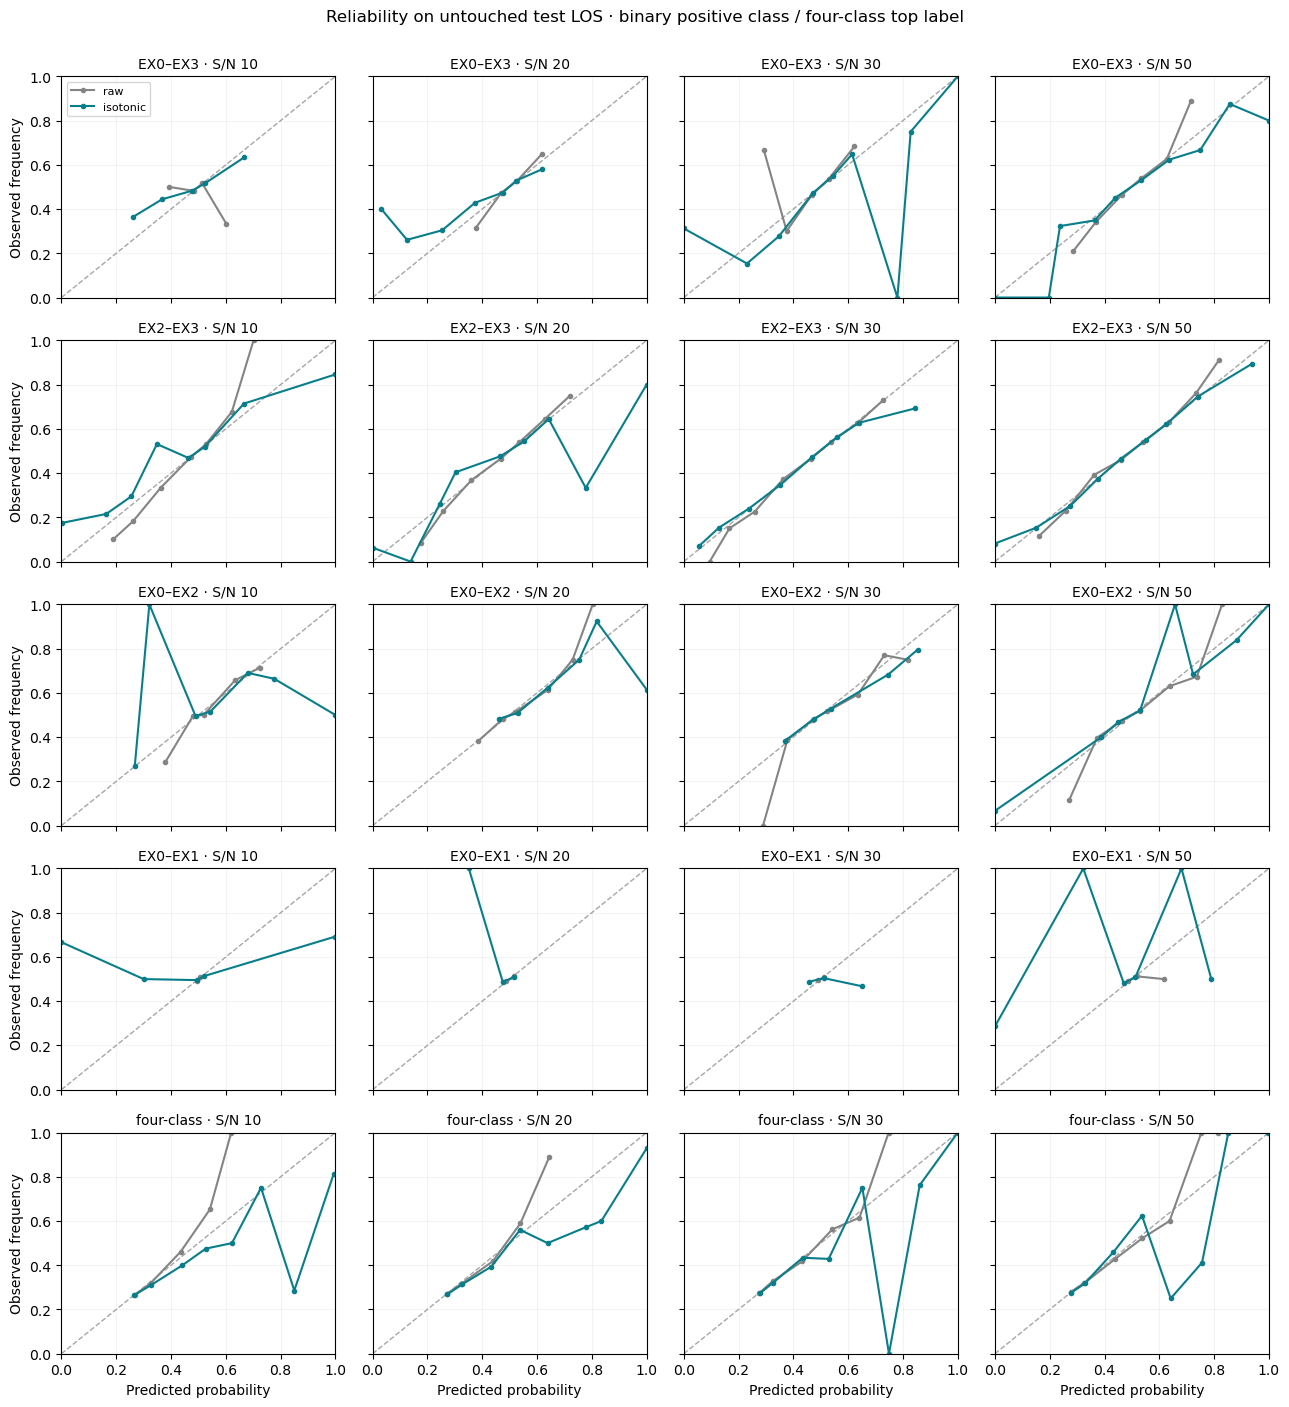

In [5]:
reliability_rows=[]
bin_edges=np.linspace(0,1,11)
for (task,snr),pred in PREDICTIONS.items():
    k=len(TASKS[task])
    for r,seed in enumerate(NOISE_SEEDS):
        y=np.repeat(np.arange(k),len(test_los))
        for calibration,name in (("raw","raw"),("calibrated","isotonic")):
            p=pred[calibration][r].reshape(-1,k)
            views=[(f"class_{model}",p[:,j],(y==j).astype(float))
                   for j,model in enumerate(TASKS[task])]
            if k>2:
                top=p.max(axis=1)
                hits=np.array([tie_credit(p[y==j],j) for j in range(k)]).ravel()
                views.append(("top_label",top,hits))
            for view,confidence,observed in views:
                bins=np.minimum(np.searchsorted(bin_edges,confidence,side="right")-1,9)
                for b in range(10):
                    mask=bins==b
                    if np.any(mask):
                        reliability_rows.append(dict(task=task,snr=snr,noise_seed=seed,
                            calibration=name,view=view,bin=b,count=int(mask.sum()),
                            mean_probability=float(confidence[mask].mean()),
                            observed_frequency=float(observed[mask].mean())))
reliability=pd.DataFrame(reliability_rows)
reliability.to_csv(OUT/"reliability_by_seed.csv",index=False)
fig,axes=plt.subplots(len(TASKS),len(PLOT_SNRS),figsize=(13,14),sharex=True,sharey=True)
for i,(task,models) in enumerate(TASKS.items()):
    view=f"class_{models[1]}" if len(models)==2 else "top_label"
    for j,snr in enumerate(PLOT_SNRS):
        ax=axes[i,j]
        ax.plot([0,1],[0,1],"--",color="0.65",lw=1)
        subset=reliability.query("task==@task and snr==@snr and view==@view")
        for name,color in (("raw","#848484"),("isotonic","#087e8b")):
            rows=[]
            for b,group in subset[subset.calibration==name].groupby("bin"):
                weight=group["count"]
                rows.append((np.average(group.mean_probability,weights=weight),
                             np.average(group.observed_frequency,weights=weight)))
            points=np.asarray(rows)
            if len(points):
                ax.plot(points[:,0],points[:,1],"o-",ms=3,color=color,label=name)
        ax.set_title(f"{TASK_LABELS[task]} · S/N {snr}",fontsize=10)
        ax.set_xlim(0,1); ax.set_ylim(0,1); ax.grid(alpha=.15)
        if j==0: ax.set_ylabel("Observed frequency")
        if i==len(TASKS)-1: ax.set_xlabel("Predicted probability")
axes[0,0].legend(fontsize=8)
fig.suptitle("Reliability on untouched test LOS · binary positive class / four-class top label",y=1.002)
fig.tight_layout()
fig.savefig(OUT/"reliability.png",dpi=180,bbox_inches="tight")
fig.savefig(OUT/"reliability.pdf",bbox_inches="tight")
plt.show()


In [6]:
# Every row has 200 distinct held-out LOS. Reused across tasks/SNR/seeds.
draw_rng=np.random.default_rng(SEED+1)
draw_indices=np.stack([draw_rng.choice(len(test_los),DIRECT_MAX_N,replace=False)
                       for _ in range(DIRECT_DRAWS)])
assert np.all(np.diff(np.sort(draw_indices,axis=1),axis=1)>0)
save_npz(OUT/"direct_draw_indices.npz",indices=draw_indices,test_los=test_los)
direct_ns=np.arange(1,DIRECT_MAX_N+1)
long_ns=np.unique(np.r_[201,np.rint(np.geomspace(201,GAUSSIAN_MAX_N,100)).astype(int)])
sobol=qmc.Sobol(d=3,scramble=True,seed=SEED+2)
normal_draws=ndtri(np.clip(sobol.random_base2(GAUSSIAN_SOBOL_POWER),1e-12,1-1e-12))


def margin_moments(probabilities):
    """Per true class: log p(true)/p(other), retaining all cross-margin covariance."""
    k=probabilities.shape[0]
    moments=[]
    for c in range(k):
        logp=np.log(probabilities[c])
        others=[j for j in range(k) if j!=c]
        margins=logp[:,[c]]-logp[:,others]
        mu=margins.mean(axis=0)
        covariance=np.atleast_2d(np.cov(margins,rowvar=False,ddof=1))
        eigval,eigvec=np.linalg.eigh(covariance)
        root=eigvec@np.diag(np.sqrt(np.maximum(eigval,0)))
        z=normal_draws[:,:k-1]@root.T
        moments.append(dict(mu=mu,cov=covariance,z=z,other_classes=others))
    return moments


def orthant_accuracy(mean,covariance,z=None):
    """Balanced tie credit for zero margins; binary analytic, joint-normal multiclass."""
    mean=np.asarray(mean,dtype=float)
    covariance=np.atleast_2d(covariance)
    if len(mean)==1:
        variance=max(float(covariance[0,0]),0)
        if variance==0:
            return float(mean[0]>0)+0.5*float(mean[0]==0)
        return float(ndtr(mean[0]/np.sqrt(variance)))
    if z is None:
        eigval,eigvec=np.linalg.eigh(covariance)
        root=eigvec@np.diag(np.sqrt(np.maximum(eigval,0)))
        z=normal_draws[:,:len(mean)]@root.T
    margins=mean+z
    # True score is 0; every competitor score is the negative margin.
    scores=np.column_stack([np.zeros(len(margins)),-margins])
    return float(tie_credit(scores,0).mean())


def gaussian_accuracy(moment,n,finite_pool=None):
    factor=float(n)
    if finite_pool is not None:
        if n>finite_pool:
            raise ValueError("Without-replacement N exceeds the test pool.")
        factor*=1-float(n)/finite_pool
    return orthant_accuracy(n*moment["mu"],factor*moment["cov"],
                            np.sqrt(factor)*moment["z"] if len(moment["mu"])>1 else None)


def direct_accuracies(probabilities):
    k=probabilities.shape[0]
    credits=[]
    for c in range(k):
        scores=np.log(probabilities[c])[draw_indices].cumsum(axis=1)
        credits.append(tie_credit(scores,c))
    credits=np.stack(credits)                  # class, draw, N
    by_class=credits.mean(axis=1)
    class_mcse=credits.std(axis=1,ddof=1)/np.sqrt(DIRECT_DRAWS)
    # Shared LOS draws across true classes: compute MCSE after class averaging.
    balanced_draws=credits.mean(axis=0)
    balanced=balanced_draws.mean(axis=0)
    balanced_mcse=balanced_draws.std(axis=0,ddof=1)/np.sqrt(DIRECT_DRAWS)
    return by_class,class_mcse,balanced,balanced_mcse


In [7]:
curve_rows=[]
check_rows=[]
MOMENTS={}
DIRECT={}
GAUSSIAN_OK={}
moment_arrays={}
for (task,snr),pred in PREDICTIONS.items():
    k=len(TASKS[task])
    for r,seed in enumerate(NOISE_SEEDS):
        p=pred["calibrated"][r]
        by_class,class_mcse,balanced,balanced_mcse=direct_accuracies(p)
        moments=margin_moments(p)
        MOMENTS[(task,snr,seed)]=moments
        DIRECT[(task,snr,seed)]=balanced
        moment_arrays[f"{task}_snr{snr}_seed{seed}_mean"]=np.stack([m["mu"] for m in moments])
        moment_arrays[f"{task}_snr{snr}_seed{seed}_cov"]=np.stack([m["cov"] for m in moments])
        checks=[]
        for n in CHECK_NS:
            for c,model in enumerate(TASKS[task]):
                approx=gaussian_accuracy(moments[c],n,finite_pool=len(test_los))
                tolerance=max(CHECK_ABS_TOL,3*float(class_mcse[c,n-1]))
                difference=approx-float(by_class[c,n-1])
                passed=abs(difference)<=tolerance
                checks.append(passed)
                check_rows.append(dict(task=task,snr=snr,noise_seed=seed,n=n,true_model=model,
                    direct_accuracy=float(by_class[c,n-1]),gaussian_accuracy=approx,
                    difference=difference,direct_mcse=float(class_mcse[c,n-1]),
                    tolerance=tolerance,passed=passed,finite_pool_size=len(test_los)))
        GAUSSIAN_OK[(task,snr,seed)]=all(checks)
        positive_drift=all(np.all(m["mu"]>0) for m in moments)
        for ix,n in enumerate(direct_ns):
            row=dict(task=task,snr=snr,noise_seed=seed,n=int(n),method="direct_without_replacement",
                     accuracy=float(balanced[ix]),mcse=float(balanced_mcse[ix]),
                     gaussian_check_passed=all(checks),all_margins_positive=positive_drift)
            row.update({f"accuracy_{model}":float(by_class[c,ix]) for c,model in enumerate(TASKS[task])})
            curve_rows.append(row)
        # Keep failed forecasts in the CSV for diagnosis; plots/N95 will mask them.
        for n in long_ns:
            values=[gaussian_accuracy(m,n) for m in moments]
            row=dict(task=task,snr=snr,noise_seed=seed,n=int(n),method="gaussian_iid",
                     accuracy=float(np.mean(values)),mcse=np.nan,
                     gaussian_check_passed=all(checks),all_margins_positive=positive_drift)
            row.update({f"accuracy_{model}":float(values[c]) for c,model in enumerate(TASKS[task])})
            curve_rows.append(row)
        print(f"Batch curves {TASK_LABELS[task]}, S/N {snr}, seed {seed}: "
              f"Gaussian check {'PASS' if all(checks) else 'FAIL'}",flush=True)
curves=pd.DataFrame(curve_rows)
checks=pd.DataFrame(check_rows)
curves.to_csv(OUT/"accuracy_vs_n_by_seed.csv",index=False)
checks.to_csv(OUT/"gaussian_validation.csv",index=False)
save_npz(OUT/"log_ratio_moments.npz",**moment_arrays,noise_seeds=np.asarray(NOISE_SEEDS),
         snr_levels=np.asarray(SNRS),metadata_json=np.array(json.dumps({
             "model_order":TASKS,"covariance_ddof":1,"training_key":TRAINING_KEY,
             "gaussian_validation":"finite-population correction N*(1-N/M); M=test LOS count",
             "forecast":"independent new chunks: covariance N*sample_covariance"})))
print("Gaussian checks (all classes, check sizes and seeds):")
display(checks.groupby(["task","snr"]).passed.all().unstack("snr"))


Batch curves EX0–EX3, S/N 10, seed 20260929: Gaussian check PASS
Batch curves EX0–EX3, S/N 10, seed 20260930: Gaussian check PASS
Batch curves EX0–EX3, S/N 10, seed 20261001: Gaussian check PASS
Batch curves EX2–EX3, S/N 10, seed 20260929: Gaussian check FAIL
Batch curves EX2–EX3, S/N 10, seed 20260930: Gaussian check FAIL
Batch curves EX2–EX3, S/N 10, seed 20261001: Gaussian check FAIL
Batch curves EX0–EX2, S/N 10, seed 20260929: Gaussian check FAIL
Batch curves EX0–EX2, S/N 10, seed 20260930: Gaussian check FAIL
Batch curves EX0–EX2, S/N 10, seed 20261001: Gaussian check FAIL
Batch curves EX0–EX1, S/N 10, seed 20260929: Gaussian check FAIL
Batch curves EX0–EX1, S/N 10, seed 20260930: Gaussian check FAIL
Batch curves EX0–EX1, S/N 10, seed 20261001: Gaussian check FAIL
Batch curves four-class, S/N 10, seed 20260929: Gaussian check FAIL
Batch curves four-class, S/N 10, seed 20260930: Gaussian check FAIL
Batch curves four-class, S/N 10, seed 20261001: Gaussian check FAIL
Batch curves EX0

snr,10,15,20,30,50,80
task,,,,,,
EX0_EX1,False,False,True,True,False,False
EX0_EX2,False,False,False,True,False,False
EX0_EX3,True,False,False,False,False,False
EX2_EX3,False,False,False,False,False,False
four_class,False,False,False,False,False,False


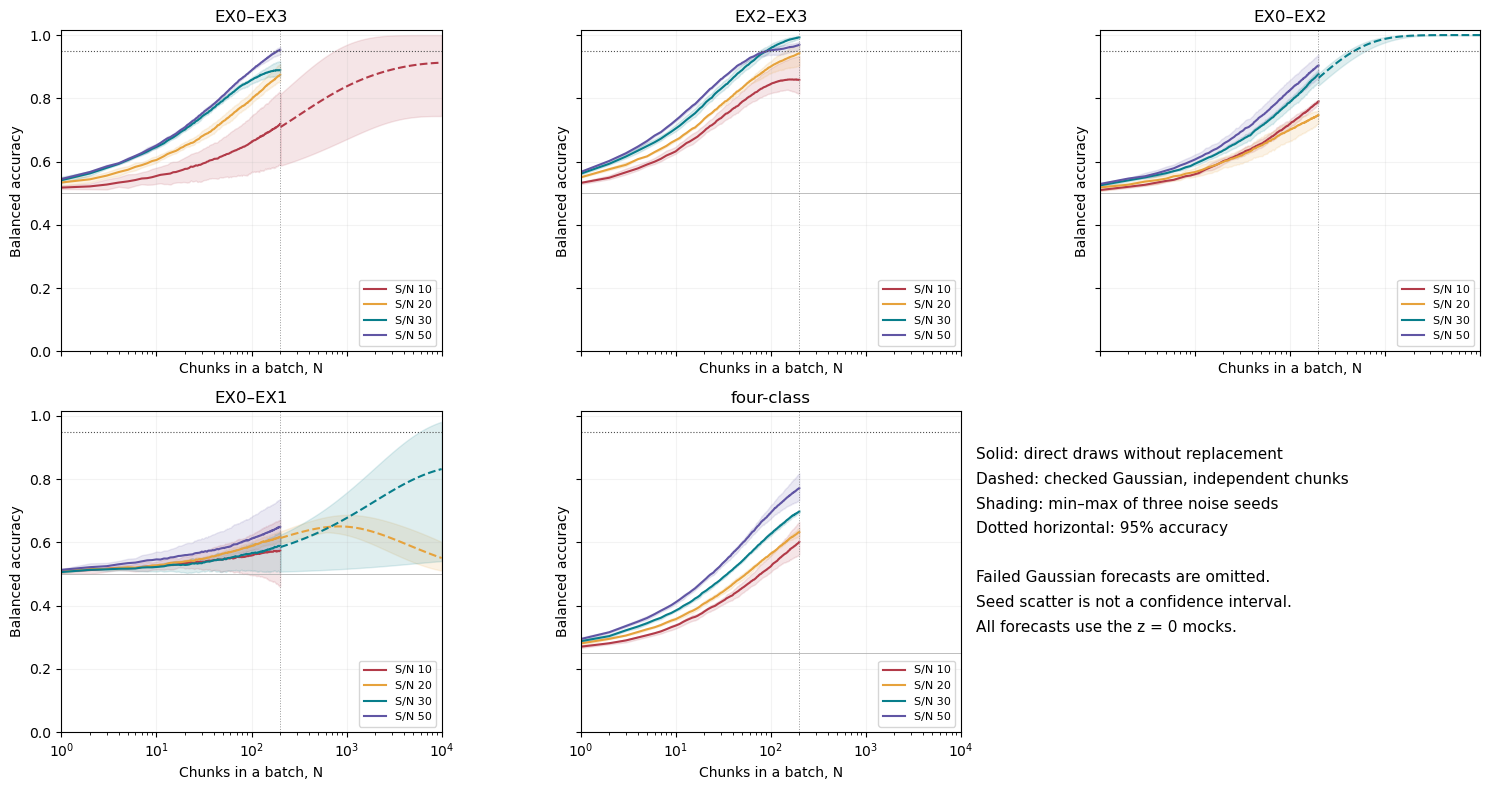

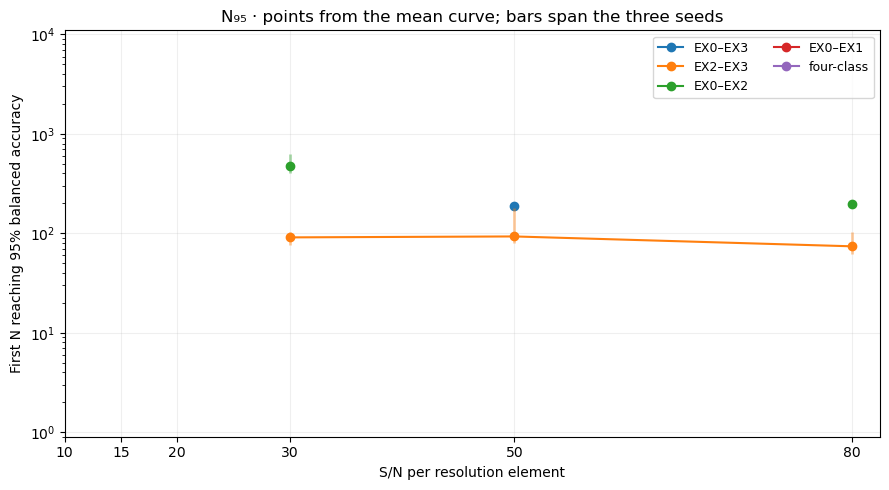

,task,snr,n95,method,sustained_through_200_or_monotone
3,EX0_EX3,10,NaN,nonpositive_margin_drift,False
7,EX0_EX3,15,NaN,gaussian_check_failed,False
11,EX0_EX3,20,NaN,gaussian_check_failed,False
15,EX0_EX3,30,NaN,gaussian_check_failed,False
19,EX0_EX3,50,189.0,direct_first_crossing,True
23,EX0_EX3,80,NaN,gaussian_check_failed,False
27,EX2_EX3,10,NaN,gaussian_check_failed,False
31,EX2_EX3,15,NaN,gaussian_check_failed,False
35,EX2_EX3,20,NaN,gaussian_check_failed,False
39,EX2_EX3,30,91.0,direct_first_crossing,True


In [8]:
summary=curves.groupby(["task","snr","n","method"],as_index=False).agg(
    accuracy=("accuracy","mean"),seed_sd=("accuracy","std"),
    seed_min=("accuracy","min"),seed_max=("accuracy","max"),
    gaussian_check_passed=("gaussian_check_passed","all"),
    all_margins_positive=("all_margins_positive","all"))
summary.to_csv(OUT/"accuracy_vs_n.csv",index=False)


def n95_estimate(task,snr,seeds):
    direct=np.mean([DIRECT[(task,snr,seed)] for seed in seeds],axis=0)
    crossing=np.flatnonzero(direct>=.95)
    if len(crossing):
        n=int(crossing[0])+1
        return n,"direct_first_crossing",bool(np.all(direct[n-1:]>=.95))
    if not all(GAUSSIAN_OK[(task,snr,s)] for s in seeds):
        return np.nan,"gaussian_check_failed",False
    moments=[m for s in seeds for m in MOMENTS[(task,snr,s)]]
    if not all(np.all(m["mu"]>0) for m in moments):
        return np.nan,"nonpositive_margin_drift",False
    def accuracy(n):
        return np.mean([gaussian_accuracy(m,n) for m in moments])
    if accuracy(GAUSSIAN_MAX_N)<.95:
        return np.nan,f"above_{GAUSSIAN_MAX_N}",False
    lo,hi=DIRECT_MAX_N+1,GAUSSIAN_MAX_N
    while lo<hi:
        mid=(lo+hi)//2
        if accuracy(mid)>=.95:
            hi=mid
        else:
            lo=mid+1
    return lo,"gaussian_iid",True


n95_rows=[]
for task in TASKS:
    for snr in SNRS:
        for name,seeds in [(str(seed),(seed,)) for seed in NOISE_SEEDS]+[("mean",NOISE_SEEDS)]:
            value,method,sustained=n95_estimate(task,snr,seeds)
            n95_rows.append(dict(task=task,snr=snr,noise_seed=name,n95=value,
                                 method=method,sustained_through_200_or_monotone=sustained))
n95=pd.DataFrame(n95_rows)
n95.to_csv(OUT/"n95_by_snr.csv",index=False)

colors={10:"#b23a48",20:"#e6a23c",30:"#087e8b",50:"#6055a4"}
fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True,sharey=True)
for ax,(task,models) in zip(axes.ravel(),TASKS.items()):
    for snr in PLOT_SNRS:
        sub=summary[(summary.task==task)&(summary.snr==snr)]
        for method,linestyle in (("direct_without_replacement","-"),("gaussian_iid","--")):
            data=sub[sub.method==method].sort_values("n")
            if method=="gaussian_iid" and not bool(data.gaussian_check_passed.all()):
                continue
            ax.plot(data.n,data.accuracy,color=colors[snr],ls=linestyle,
                    label=f"S/N {snr}" if method=="direct_without_replacement" else None)
            ax.fill_between(data.n.to_numpy(),data.seed_min.to_numpy(),data.seed_max.to_numpy(),
                            color=colors[snr],alpha=.13)
    ax.axhline(.95,color="0.3",lw=.8,ls=":")
    ax.axhline(1/len(models),color="0.7",lw=.6)
    ax.axvline(200,color="0.6",lw=.7,ls=":")
    ax.set_xscale("log"); ax.set_ylim(0,1.015); ax.set_xlim(1,GAUSSIAN_MAX_N)
    ax.set_title(TASK_LABELS[task]); ax.set_xlabel("Chunks in a batch, N")
    ax.set_ylabel("Balanced accuracy"); ax.grid(alpha=.15)
    ax.legend(fontsize=8,loc="lower right")
axes.ravel()[-1].axis("off")
axes.ravel()[-1].text(.05,.9,"Solid: direct draws without replacement\n"
    "Dashed: checked Gaussian, independent chunks\nShading: min–max of three noise seeds\n"
    "Dotted horizontal: 95% accuracy\n\nFailed Gaussian forecasts are omitted.\n"
    "Seed scatter is not a confidence interval.\nAll forecasts use the z = 0 mocks.",
    va="top",fontsize=11,linespacing=1.8)
fig.tight_layout()
fig.savefig(OUT/"accuracy_vs_n.png",dpi=180,bbox_inches="tight")
fig.savefig(OUT/"accuracy_vs_n.pdf",bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(9,5))
for task in TASKS:
    data=n95[(n95.task==task)&(n95.noise_seed=="mean")].sort_values("snr")
    line=ax.plot(data.snr,data.n95,"o-",label=TASK_LABELS[task])[0]
    seeds=n95[(n95.task==task)&(n95.noise_seed!="mean")]
    for snr,group in seeds.groupby("snr"):
        finite=group.n95.dropna()
        if len(finite)==len(NOISE_SEEDS):
            ax.vlines(snr,finite.min(),finite.max(),color=line.get_color(),alpha=.4,lw=2)
ax.set_yscale("log"); ax.set_ylim(.9,GAUSSIAN_MAX_N*1.1)
ax.set_xticks(SNRS); ax.set_xlabel("S/N per resolution element")
ax.set_ylabel("First N reaching 95% balanced accuracy")
ax.set_title("N₉₅ · points from the mean curve; bars span the three seeds")
ax.legend(ncol=2,fontsize=9); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/"n95_vs_snr.png",dpi=180,bbox_inches="tight")
fig.savefig(OUT/"n95_vs_snr.pdf",bbox_inches="tight")
plt.show()
display(n95[n95.noise_seed=="mean"][["task","snr","n95","method",
                                        "sustained_through_200_or_monotone"]])


In [9]:
baseline_path=ROOT/"outputs/cos_lsf_snr/snr_sweep/summary/bootstrap_inputs.npz"
comparison_rows=[]
baseline_missing=[]
baseline_summary=None
if baseline_path.is_file():
    with np.load(baseline_path,allow_pickle=False) as saved:
        baseline_summary={key:saved[key] for key in saved.files}


def bundled_accuracies(task,snr,seed):
    """One balanced score per original held-out bundle, in sorted bundle-ID order."""
    if baseline_summary is not None:
        task_names=[str(x) for x in baseline_summary["task_names"]]
        if TASK_LABELS[task] in task_names:
            t=task_names.index(TASK_LABELS[task])
            s=list(baseline_summary["snr_levels"]).index(snr)
            r=list(baseline_summary["noise_seeds"]).index(seed)
            ids=baseline_summary["test_bundle_ids"]
            lookup={int(b):i for i,b in enumerate(ids)}
            order=[lookup[int(b)] for b in test_bundle_ids]
            return baseline_summary["noisy_bundle_accuracy"][t,s,r,order]
    models=TASKS[task]
    path=(ROOT/"outputs/cos_lsf_snr/snr_sweep/runs"/f"snr{snr}_seed{seed}"
          /"z0_b15_s42"/"matched"/"_".join(models)/"predictions.npz")
    if not path.is_file():
        raise FileNotFoundError(str(path))
    with np.load(path,allow_pickle=False) as saved:
        y=saved["y_true"]; predicted=saved["y_pred"]
        ids=saved["bundle_ids"]; sources=saved["source_models"].astype(str)
        scores=[]
        for model in models:
            rows=np.flatnonzero(sources==model)
            lookup={int(ids[i]):int(i) for i in rows}
            if len(lookup)!=len(test_bundle_ids):
                raise ValueError(f"Wrong baseline bundles: {path}")
            order=[lookup[int(b)] for b in test_bundle_ids]
            scores.append((y[order]==predicted[order]).astype(float))
    return np.mean(scores,axis=0)


bootstrap_rng=np.random.default_rng(SEED+3)
bootstrap_weights=bootstrap_rng.multinomial(len(test_bundle_ids),
    np.full(len(test_bundle_ids),1/len(test_bundle_ids)),size=BASELINE_BOOTSTRAPS)
for task,models in TASKS.items():
    for snr in SNRS:
        per_chunk=[]; bundled=[]
        for r,seed in enumerate(NOISE_SEEDS):
            p=PREDICTIONS[(task,snr)]["calibrated"][r]
            logp=np.log(p).reshape(len(models),len(test_bundle_ids),bundle_size,len(models)).sum(axis=2)
            chunk_score=np.mean([tie_credit(logp[c],c) for c in range(len(models))],axis=0)
            try:
                baseline=bundled_accuracies(task,snr,seed)
            except FileNotFoundError as error:
                baseline_missing.append(str(error))
                continue
            per_chunk.append(chunk_score); bundled.append(baseline)
            comparison_rows.append(dict(task=task,snr=snr,noise_seed=str(seed),
                per_chunk_accuracy=float(chunk_score.mean()),bundled_accuracy=float(baseline.mean()),
                difference=float((chunk_score-baseline).mean()),low=np.nan,high=np.nan))
        if len(per_chunk)==len(NOISE_SEEDS):
            pc=np.mean(per_chunk,axis=0); bb=np.mean(bundled,axis=0)
            delta=bootstrap_weights@(pc-bb)/len(test_bundle_ids)
            lo,hi=np.quantile(delta,[.025,.975])
            comparison_rows.append(dict(task=task,snr=snr,noise_seed="mean",
                per_chunk_accuracy=float(pc.mean()),bundled_accuracy=float(bb.mean()),
                difference=float((pc-bb).mean()),low=float(lo),high=float(hi)))
comparison=pd.DataFrame(comparison_rows)
comparison.to_csv(OUT/"n15_vs_bundled.csv",index=False)
if not comparison.empty:
    display(comparison[comparison.noise_seed=="mean"])
if baseline_missing:
    print(f"Missing {len(baseline_missing)} baseline predictions; other results are unaffected.")
    print(baseline_missing[0])


,task,snr,noise_seed,per_chunk_accuracy,bundled_accuracy,difference,low,high
3,EX0_EX3,10,mean,0.572139,0.570896,0.001244,-0.047295,0.049751
7,EX0_EX3,15,mean,0.610697,0.577114,0.033582,-0.008706,0.077114
11,EX0_EX3,20,mean,0.636816,0.590796,0.046020,0.008706,0.084577
15,EX0_EX3,30,mean,0.674129,0.639303,0.034826,-0.002488,0.072139
19,EX0_EX3,50,mean,0.686567,0.655473,0.031095,-0.008706,0.068408
23,EX0_EX3,80,mean,0.691542,0.670398,0.021144,-0.012438,0.055970
27,EX2_EX3,10,mean,0.672886,0.649254,0.023632,-0.011194,0.058458
31,EX2_EX3,15,mean,0.692786,0.672886,0.019900,-0.019900,0.058458
35,EX2_EX3,20,mean,0.710199,0.671642,0.038557,0.001244,0.074627
39,EX2_EX3,30,mean,0.752488,0.695274,0.057214,0.023632,0.090796


In [10]:
qa_rows=[]
qa_status="missing_snr_counts"
if QA_MIX_CSV is None:
    print("QA forecast pending: set QA_MIX_CSV to your QA counts CSV (snr_resel,n_chunks). "
          "The total 1,113 does not determine the S/N mixture.")
else:
    qa_path=Path(QA_MIX_CSV)
    if not qa_path.is_absolute(): qa_path=ROOT/qa_path
    mix=pd.read_csv(qa_path)
    if not {"snr_resel","n_chunks"}.issubset(mix.columns):
        raise ValueError("QA CSV requires snr_resel,n_chunks.")
    values=mix[["snr_resel","n_chunks"]].to_numpy(dtype=float)
    if (not np.all(np.isfinite(values)) or np.any(values[:,1]<0)
            or np.any(values!=np.floor(values))):
        raise ValueError("Use finite integer S/N grid values and nonnegative integer chunk counts.")
    mix=mix[["snr_resel","n_chunks"]].astype(int).groupby("snr_resel",as_index=False).n_chunks.sum()
    mix=mix[mix.n_chunks>0]
    if not set(mix.snr_resel).issubset(SNRS):
        raise ValueError("QA S/N bins must match cached S/N values exactly. No silent rounding or extrapolation.")
    if int(mix.n_chunks.sum())!=EXPECTED_QA_CHUNKS:
        raise ValueError(f"QA counts must sum to {EXPECTED_QA_CHUNKS}.")
    mix.to_csv(OUT/"qa_snr_mix_used.csv",index=False)
    for task,models in TASKS.items():
        if len(models)!=2: continue
        seed_values=[]
        for seed in NOISE_SEEDS:
            passed=all(GAUSSIAN_OK[(task,int(s),seed)] for s in mix.snr_resel)
            class_values=[]
            for c,model in enumerate(models):
                mu=np.zeros(1); cov=np.zeros((1,1))
                for row in mix.itertuples(index=False):
                    moment=MOMENTS[(task,int(row.snr_resel),seed)][c]
                    mu+=int(row.n_chunks)*moment["mu"]
                    cov+=int(row.n_chunks)*moment["cov"]
                class_values.append(orthant_accuracy(mu,cov))
            value=float(np.mean(class_values)) if passed else np.nan
            seed_values.append(value)
            qa_rows.append(dict(task=task,noise_seed=str(seed),n_chunks=EXPECTED_QA_CHUNKS,
                expected_accuracy=value,gaussian_check_passed=passed,
                accuracy_class0=class_values[0] if passed else np.nan,
                accuracy_class1=class_values[1] if passed else np.nan,
                seed_min=np.nan,seed_max=np.nan))
        good=bool(np.all(np.isfinite(seed_values)))
        qa_rows.append(dict(task=task,noise_seed="mean",n_chunks=EXPECTED_QA_CHUNKS,
            expected_accuracy=float(np.mean(seed_values)) if good else np.nan,
            gaussian_check_passed=good,accuracy_class0=np.nan,accuracy_class1=np.nan,
            seed_min=float(np.min(seed_values)) if good else np.nan,
            seed_max=float(np.max(seed_values)) if good else np.nan))
    qa_status="computed_with_check_flags"
qa=pd.DataFrame(qa_rows,columns=["task","noise_seed","n_chunks","expected_accuracy",
    "gaussian_check_passed","accuracy_class0","accuracy_class1","seed_min","seed_max"])
qa.to_csv(OUT/"qa_1113_chunk_forecast.csv",index=False)
if not qa.empty:
    result=qa[qa.noise_seed=="mean"][["task","expected_accuracy","seed_min","seed_max",
                                        "gaussian_check_passed"]]
    formatted=result.copy()
    for column in ("expected_accuracy","seed_min","seed_max"):
        formatted[column]=formatted[column].map(lambda value:"—" if pd.isna(value) else f"{value:.2%}")
    display(formatted)
    print("z = 0 mock forecast with independent chunks and equal class priors; "
          "not measured accuracy on the observed spectra.")
provenance={"training_key":TRAINING_KEY,"qa_status":qa_status,"task_models":TASKS,
    "snr_levels":SNRS,"noise_seeds":NOISE_SEEDS,"direct_draws":DIRECT_DRAWS,
    "direct_max_n":DIRECT_MAX_N,"gaussian_max_n":GAUSSIAN_MAX_N,
    "gaussian_check_n":CHECK_NS,"gaussian_check_abs_tolerance":CHECK_ABS_TOL,
    "gaussian_sobol_power":GAUSSIAN_SOBOL_POWER,"epsilon":EPS,
    "baseline_bootstraps":BASELINE_BOOTSTRAPS,
    "group_counts_per_class":{"fit":len(fit_los),"tuning":len(tune_los),
        "isotonic":len(calibration_los),"test":len(test_los)},
    "definitions":{"accuracy":"Equal-prior balanced accuracy with fractional credit for exact ties",
        "seed_scatter":"Across three fixed noise realizations; not three independent surveys",
        "mcse":"Monte Carlo sampling precision conditional on the fixed held-out pool",
        "direct":"N<=200, distinct LOS within each batch; one true model per batch",
        "gaussian":"Independent new chunks; class-conditional LLR mean and full covariance",
        "n95":"First integer crossing; direct through 200, checked monotone Gaussian thereafter",
        "n15":"Same frozen test bundles; paired bootstrap over bundles of the seed-mean difference",
        "qa":"Sum S/N-specific LLR means and covariances for a fixed 1,113-chunk mix; z=0 only"}}
if QA_MIX_CSV is not None:
    provenance["qa_mix_sha256"]=file_hash(qa_path)
if baseline_path.is_file():
    provenance["bundled_summary_sha256"]=file_hash(baseline_path)
write_json(OUT/"analysis_provenance.json",provenance)
print(f"Completed. Outputs: {OUT}")


QA forecast pending: set QA_MIX_CSV to your QA counts CSV (snr_resel,n_chunks). The total 1,113 does not determine the S/N mixture.
Completed. Outputs: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/perchunk_tuned
